# Modeling: experiments beyond defaults (E3–E6, Mac)

`02` gave us E0 (pretrained, no training) and E1 (fine-tune with Ultralytics defaults, selection metric 0.455). This notebook changes **one factor at a time** against E1 and writes the hypothesis down **before** each run. Image size (E2) is in `06`, on a Colab GPU.

| § | Experiment | Runs | Why |
|---|---|---|---|
| 1 | E1 seeds | seed 1, seed 2 | How much does the score move by chance? Every later verdict needs this yardstick. |
| 2 | NMS IoU | none, val only | Error analysis hypothesis #6: duplicate rider boxes. |
| 3 | E3 frozen layers | `freeze=11`, `freeze=23` | Does keeping COCO's features fixed help with 48 images? |
| 4 | E4 augmentation | `scale=0.3`, `mosaic=0.5` | Do the default augmentations hurt our tiny ball? |
| 5 | E5 epochs | 50, 200 | Is 100 epochs too short or too long? |
| 6 | E6 model size | `yolo26n`, `yolo26m` | Accuracy against speed. |

All at `imgsz=640` on the Mac (M4, `mps`), about 12 min per run, 2–3 hours in total. 640 is a **screening** size: the Mac can't train at 1280. Whatever wins here is checked once more at the size E2 picks, on Colab.

**Reading the results:** val has 25 frames, so one ball is worth about 4 points of ball AP50. A difference smaller than the spread between E1 seeds (§1) is not evidence.

> **GenAI:** written with Claude Code on 2026-11-11: code, hypothesis texts (from `modeling/README.md` §5–§6, the E1 curves and the error-analysis hypotheses in `03_error_analysis.ipynb` §7), and a check of the Ultralytics 8.4.192 source for mosaic and checkpoints. Details in [`modeling/README.md` §12](../modeling/README.md#12-genai-disclosure). What we checked or changed ourselves: _to fill in_.

## 0. Setup

In [1]:
import os
os.environ["YOLO_VERBOSE"] = "False"   # before importing ultralytics: no per-epoch logs (the numbers are in each run's results.csv)

import warnings
warnings.filterwarnings("ignore", message=".*does not have a deterministic implementation")   # MPS notice, once per batch
from pathlib import Path

import pandas as pd
import torch
import ultralytics
from IPython.display import Image, display
from ultralytics import YOLO

ROOT = Path.cwd().parent                     # this notebook lives in notebooks/
VERSION = "v1b"                               # dataset version, part of every run name
DATA = ROOT / "data/cycle-ball-dataset"
RUNS = ROOT / "runs/modeling"                # git-ignored
MODEL = "yolo26s.pt"
ARCH = Path(MODEL).stem
DEVICE = "mps" if torch.backends.mps.is_available() else 0 if torch.cuda.is_available() else "cpu"

n = {s: len(list((DATA / "images" / s).glob("*.jpg"))) for s in ("train", "val")}
assert n == {"train": 48, "val": 25}, f"expected dataset {VERSION} (48 train / 25 val), found {n}"
print("dataset", VERSION, n, "| ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| device", DEVICE)

dataset v1b {'train': 48, 'val': 25} | ultralytics 8.4.192 | torch 2.15.0 | device mps


### Helpers

- `train(name, **overrides)`: trains with E1's settings (defaults, `imgsz=640`, `seed=0`) plus the one factor we change. A finished run is skipped, so re-running the notebook only re-validates. A run that was cut off (crash, closed laptop, Colab disconnect) is resumed from `last.pt`: Ultralytics marks a finished checkpoint with `epoch = -1` (`strip_optimizer` in `utils/torch_utils.py`).
- `evaluate(label, best)`: validates `best.pt` on val and returns one row: ball AP50 and AP50-95, player and bike AP50-95, the **selection metric** (mean AP50-95 over ball, player and bike; `goal` is near-perfect and left out), the all-class mAP YOLO reports, the epoch `best.pt` came from, training time and inference ms per image. `save_json=True` writes `predictions.json` for the error analysis.
- `show(rows, ref, noise)`: the comparison table. `Δ selection` is the difference with the reference; `beyond noise` says whether it is larger than the spread between E1 seeds (07 §1).

In [2]:
CLASSES = ("ball", "player", "bike")   # selection metric = mean AP50-95 over these; goal is near-perfect and left out
VAL = {}                               # label -> full val result, for cells that need more than the table


def train(name, model=MODEL, **overrides):
    """Train into RUNS/name and return its best.pt. A finished run is skipped, a run that was cut off is resumed."""
    last = RUNS / name / "weights/last.pt"
    if not last.exists() and last.with_name("best.pt").exists():   # finished run whose last.pt was deleted (Ultralytics saves last.pt before best.pt)
        return last.with_name("best.pt")
    if not last.exists():
        args = dict(data=str(DATA / "data.yaml"), imgsz=640, seed=0, device=DEVICE, project=str(RUNS), name=name, exist_ok=True)
        YOLO(model).train(**args | overrides)
    elif torch.load(last, map_location="cpu", weights_only=False)["epoch"] != -1:   # Ultralytics sets epoch to -1 when a run finishes
        YOLO(last).train(resume=True)
    return RUNS / name / "weights/best.pt"


def evaluate(label, best, imgsz=640, suffix="", **kw):
    """Validate best.pt on val and return one table row. Extra keyword arguments go to val (e.g. iou=0.5)."""
    run = best.parent.parent
    r = YOLO(best).val(data=str(DATA / "data.yaml"), imgsz=imgsz, device=DEVICE, project=str(RUNS),
                       name=f"{run.name}_val{suffix}", save_json=True, exist_ok=True, **kw)
    VAL[label] = r
    ap = {r.names[c]: (r.box.ap50[i], r.box.ap[i]) for i, c in enumerate(r.box.ap_class_index)}
    log = pd.read_csv(run / "results.csv")
    fitness = log["metrics/mAP50-95(B)"]           # what Ultralytics 8.4.192 uses to pick best.pt
    return {
        "run": label,
        "ball AP50": ap["ball"][0],
        "ball AP50-95": ap["ball"][1],
        "player AP50-95": ap["player"][1],
        "bike AP50-95": ap["bike"][1],
        "selection": sum(ap[c][1] for c in CLASSES) / len(CLASSES),
        "mAP50 all": r.box.map50,
        "mAP50-95 all": r.box.map,
        "best epoch": f"{int(log.epoch[fitness.idxmax()])} / {len(log)}",
        "train min": log.time.iloc[-1] / 60,
        "ms / img": r.speed["inference"],
    }


def show(rows, ref=None, noise=None):
    """Comparison table. With ref: the difference in the selection metric. With noise: whether it beats the seed spread."""
    df = pd.DataFrame(rows).set_index("run")
    if ref is not None:
        df.insert(df.columns.get_loc("selection") + 1, "Δ selection", df["selection"] - ref)
    if noise is not None:
        df.insert(df.columns.get_loc("Δ selection") + 1, "beyond noise", df["Δ selection"].abs() > noise)
    display(df.round(3))
    return df

## 1. Reference: E1 and how noisy it is

E1 (`02` §3) was trained once, with `seed=0`. Here we train it twice more with seeds 1 and 2; seed 0 is the existing run, so it is only re-validated. Even with the same seed, `mps` is not fully deterministic.

**Hypothesis:** the selection metric moves by about 0.01–0.02 between seeds, mostly through the ball (25 balls, each worth ~4 points of ball AP50). The mean of the three seeds is the reference for every later run, and the range is the noise yardstick.

In [3]:
seed_rows = [evaluate(f"E1 seed {s}", train(f"E1_{ARCH}_640_{VERSION}" + (f"_s{s}" if s else ""), seed=s)) for s in (0, 1, 2)]
sel = pd.Series([r["selection"] for r in seed_rows])
REF, NOISE = sel.mean(), sel.max() - sel.min()
show(seed_rows, ref=REF)
print(f"E1 selection metric over 3 seeds: {REF:.3f} ± {sel.std():.3f} (range {NOISE:.3f})")

,ball AP50,ball AP50-95,player AP50-95,bike AP50-95,selection,Δ selection,mAP50 all,mAP50-95 all,best epoch,train min,ms / img
run,,,,,,,,,,,
E1 seed 0,0.521,0.226,0.552,0.587,0.455,-0.013,0.840,0.590,84 / 100,11.656,9.777
E1 seed 1,0.573,0.285,0.542,0.610,0.479,0.011,0.863,0.608,84 / 100,12.571,7.212
E1 seed 2,0.568,0.275,0.533,0.606,0.471,0.003,0.859,0.602,92 / 100,11.582,7.471


E1 selection metric over 3 seeds: 0.468 ± 0.012 (range 0.024)


## 2. NMS IoU 0.5 instead of 0.7 (no training)

After the model predicts, **NMS** (non-maximum suppression) keeps the highest-scoring box and removes every other box of the same class that overlaps it by more than `iou` (default 0.7). Only validation changes, so the E1 weights are reused.

**Hypothesis (error analysis #6):** 6 of the 12 extra player boxes on val are duplicates on real riders. A stricter `iou=0.5` removes them, so **player precision goes up**. The risk: in the scrum two real riders can overlap by more than 0.5, and one of them is removed, so **player recall may drop**. AP50 about the same.

P and R are printed per class at the confidence where YOLO's mean F1 is highest; mAP doesn't depend on a threshold.

In [4]:
best_e1 = RUNS / f"E1_{ARCH}_640_{VERSION}/weights/best.pt"
nms_rows = [evaluate("E1, NMS iou 0.7", best_e1), evaluate("E1, NMS iou 0.5", best_e1, suffix="_iou05", iou=0.5)]
show(nms_rows, ref=nms_rows[0]["selection"])
for label in ("E1, NMS iou 0.7", "E1, NMS iou 0.5"):
    r = VAL[label]
    for i, c in enumerate(r.box.ap_class_index):
        if r.names[c] in ("player", "bike"):
            p, rec, ap50, _ = r.box.class_result(i)
            print(f"{label:<16} {r.names[c]:<7} P={p:.3f}  R={rec:.3f}  AP50={ap50:.3f}")

,ball AP50,ball AP50-95,player AP50-95,bike AP50-95,selection,Δ selection,mAP50 all,mAP50-95 all,best epoch,train min,ms / img
run,,,,,,,,,,,
"E1, NMS iou 0.7",0.521,0.226,0.552,0.587,0.455,0.000,0.840,0.590,84 / 100,11.656,6.942
"E1, NMS iou 0.5",0.547,0.237,0.530,0.582,0.450,-0.006,0.839,0.586,84 / 100,11.656,7.227


E1, NMS iou 0.7  player  P=0.946  R=0.895  AP50=0.934
E1, NMS iou 0.7  bike    P=0.905  R=0.787  AP50=0.910
E1, NMS iou 0.5  player  P=0.936  R=0.897  AP50=0.897
E1, NMS iou 0.5  bike    P=0.810  R=0.865  AP50=0.919


## 3. E3: frozen layers

`freeze=N` keeps layers `model.0` … `model.N-1` at their COCO weights. In YOLO26s, layers 0–10 are the backbone, 11–22 the neck, 23 the Detect head (`modeling/README.md` §5).

- `freeze=11`: backbone frozen, neck and head train.
- `freeze=23`: backbone and neck frozen, only the head trains.

**Hypothesis:** the usual reason to freeze is overfitting on small data, but E1 shows none: val loss is still falling at epoch 100 (lowest at epoch 99), and mAP50-95 plateaus around 0.57–0.59 from epoch 50. So:
- `freeze=11` ties or loses a little. The loss is on the **ball**: E0's ball AP50 of 0.147 shows COCO's features don't fit a tiny blurred ball, so the backbone needs to adapt. Player and bike within noise. Trains faster (no backward pass through the backbone).
- `freeze=23` loses clearly, most on the ball.

In [5]:
E3 = [evaluate(f"E3 freeze={k}", train(f"E3_{ARCH}_640_{VERSION}_f{k}", freeze=k)) for k in (11, 23)]
show(E3, ref=REF, noise=NOISE);

,ball AP50,ball AP50-95,player AP50-95,bike AP50-95,selection,Δ selection,beyond noise,mAP50 all,mAP50-95 all,best epoch,train min,ms / img
run,,,,,,,,,,,,
E3 freeze=11,0.456,0.260,0.578,0.585,0.474,0.006,False,0.833,0.604,64 / 100,7.332,7.162
E3 freeze=23,0.297,0.191,0.554,0.525,0.423,-0.045,True,0.781,0.565,84 / 100,5.728,6.758


## 4. E4: augmentation

**Scale.** Every training image is zoomed by a random factor in `[1 - scale, 1 + scale]`, so `[0.5, 1.5]` with the default `scale=0.5` (`RandomPerspective`, `ultralytics/data/augment.py`). At 0.5 our ~8 px ball becomes ~4 px. The camera is fixed, so val never shows such a zoom.

**Hypothesis:** `scale=0.3` (`[0.7, 1.3]`, smallest ball ~5.6 px) helps the ball a little, AP50-95 more than AP50. Player and bike about the same.

**Mosaic.** Checked in the Ultralytics 8.4.192 source (`Mosaic` and `RandomPerspective`): mosaic does **not** shrink the images. Each frame is resized to 640 on its long side as usual, four frames are pasted around a random centre of a 1280 × 1280 canvas, and a 640 × 640 window is cut from the middle (any zoom comes from `scale`). *This corrects `modeling/README.md` §6, which said each tile is downsized by about half.* What mosaic does change for us: our frames are 2.8 : 1, so without mosaic one frame fills only 640 × 228 of the 640 × 640 input, and 64% is grey padding. A mosaic input is roughly 70% picture, from parts of four frames, so it holds more riders, bikes and balls.

**Hypothesis:** `mosaic=0.5` (half the images without mosaic) lowers ball AP a little, because each step sees fewer balls. Player and bike about the same. Mosaic is switched off for the last 10 epochs in both runs (`close_mosaic=10`).

In [6]:
E4 = [evaluate("E4 scale=0.3", train(f"E4_{ARCH}_640_{VERSION}_scale03", scale=0.3)),
      evaluate("E4 mosaic=0.5", train(f"E4_{ARCH}_640_{VERSION}_mosaic05", mosaic=0.5))]
show(E4, ref=REF, noise=NOISE);

,ball AP50,ball AP50-95,player AP50-95,bike AP50-95,selection,Δ selection,beyond noise,mAP50 all,mAP50-95 all,best epoch,train min,ms / img
run,,,,,,,,,,,,
E4 scale=0.3,0.536,0.228,0.586,0.592,0.468,0.000,False,0.857,0.599,57 / 100,12.143,7.210
E4 mosaic=0.5,0.515,0.241,0.536,0.595,0.457,-0.011,False,0.849,0.590,84 / 100,12.649,7.322


## 5. E5: number of epochs

With 48 train images and `batch=16` there are 3 batches per epoch, and gradients are accumulated to a nominal batch of 64, so 100 epochs is only about 75 optimizer steps (`modeling/README.md` §8.3). The learning rate decays over the whole run, so a 50-epoch run is *not* the same as stopping a 100-epoch run halfway.

**Hypothesis:** E1's best epoch was 84 of 100 and val loss was still falling at the end.
- 200 epochs (`patience=50`: stop after 50 epochs without improvement): a small gain, probably within noise, with the best epoch well past 100.
- 50 epochs (~37 optimizer steps): a little lower, mostly on the ball, the class that learns slowest.

In [7]:
E5 = [evaluate("E5 50 epochs", train(f"E5_{ARCH}_640_{VERSION}_ep50", epochs=50)),
      evaluate("E5 200 epochs, patience 50", train(f"E5_{ARCH}_640_{VERSION}_ep200", epochs=200, patience=50))]
show(E5, ref=REF, noise=NOISE);

,ball AP50,ball AP50-95,player AP50-95,bike AP50-95,selection,Δ selection,beyond noise,mAP50 all,mAP50-95 all,best epoch,train min,ms / img
run,,,,,,,,,,,,
E5 50 epochs,0.435,0.160,0.590,0.598,0.450,-0.019,False,0.844,0.586,43 / 50,6.313,7.511
"E5 200 epochs, patience 50",0.579,0.297,0.543,0.588,0.476,0.008,False,0.866,0.606,111 / 161,19.649,6.872


Training curves of the 200-epoch run: does val loss turn up (overfitting), or keep falling?

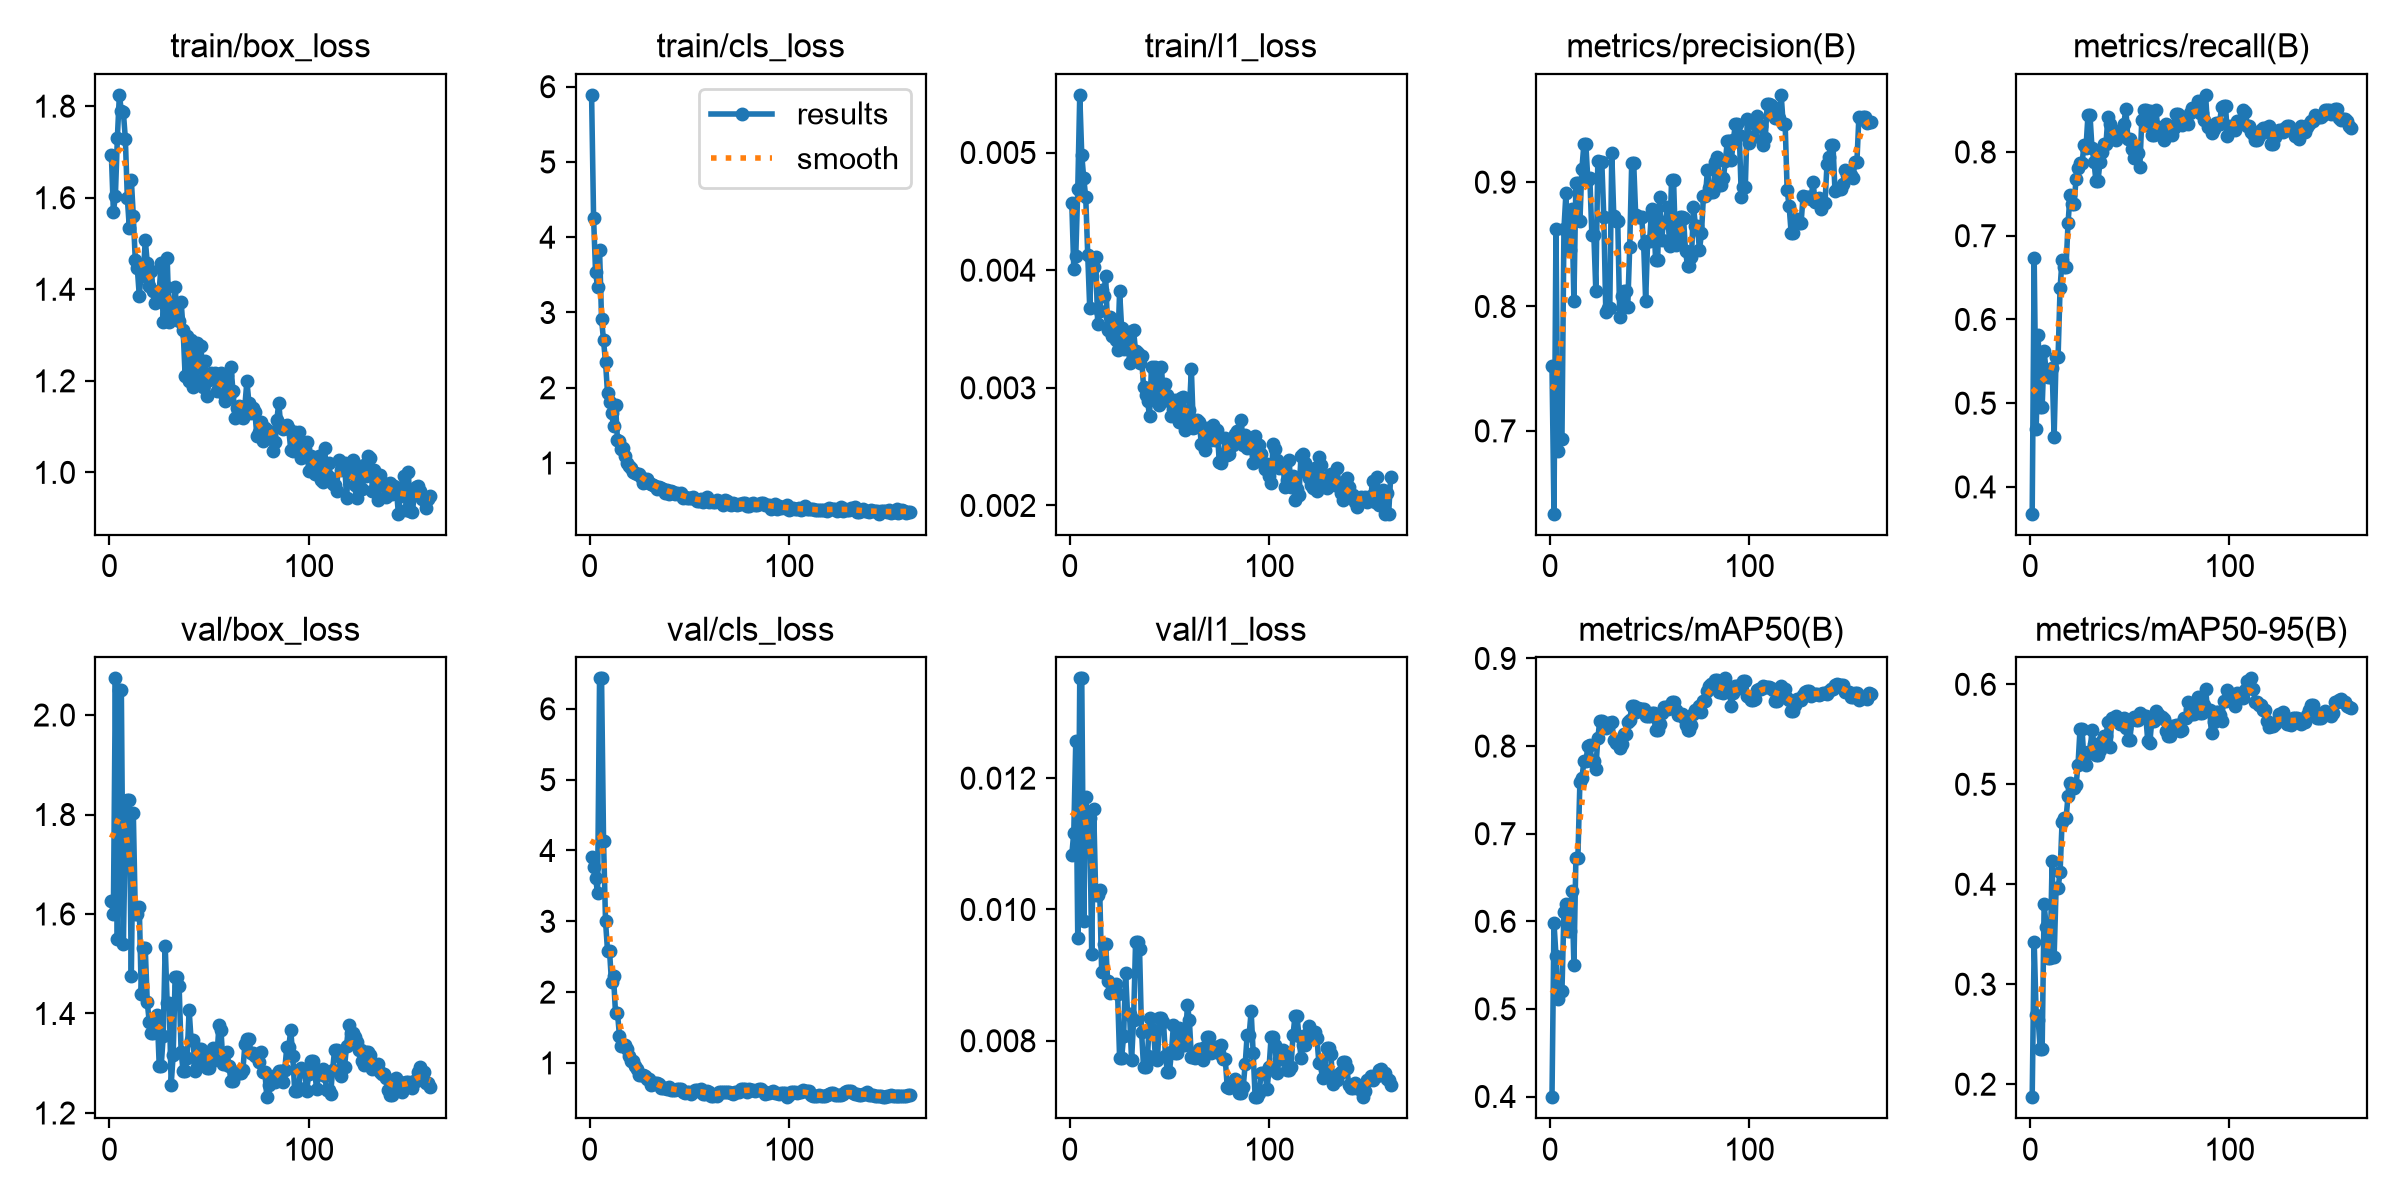

In [8]:
display(Image(filename=str(RUNS / f"E5_{ARCH}_640_{VERSION}_ep200/results.png"), width=900))

## 6. E6: model size

Same family, same settings: `yolo26n` (nano), `yolo26s` (E1), `yolo26m` (medium). **`m` runs with `batch=8`.** At `batch=16` it filled the Mac's 16 GB and swapped: no epoch finished in 17 min (11 Nov), so we stopped it. With `batch=8` Ultralytics accumulates 8 batches instead of 4 before each optimizer step (nominal batch 64, `nbs`), so the number and size of the steps stay the same as E1. Only BatchNorm sees 8 images at a time instead of 16.

**Hypothesis:**
- `n` is lower on ball and bike, the small and overlapping objects that need the most capacity. Faster.
- `m` is at most slightly better: 48 images may not be enough to use the extra capacity. Slower, about 2× the ms per image of `s`.
- Speed matters less than it seems: the app reads precomputed detections, so ms per image only sets how long a new clip takes to process.

In [9]:
E6 = [evaluate("E6 yolo26n", train(f"E6_yolo26n_640_{VERSION}", model="yolo26n.pt")),
      evaluate("E6 yolo26m (batch 8)", train(f"E6_yolo26m_640_{VERSION}_b8", model="yolo26m.pt", batch=8))]   # batch 16 swapped, see above
show(E6, ref=REF, noise=NOISE);

,ball AP50,ball AP50-95,player AP50-95,bike AP50-95,selection,Δ selection,beyond noise,mAP50 all,mAP50-95 all,best epoch,train min,ms / img
run,,,,,,,,,,,,
E6 yolo26n,0.235,0.122,0.569,0.551,0.414,-0.055,True,0.772,0.559,68 / 100,6.163,7.264
E6 yolo26m (batch 8),0.651,0.323,0.581,0.604,0.503,0.034,True,0.890,0.626,90 / 100,29.812,21.384


## 7. All runs

Every run against the E1 seed mean. `beyond noise` = the difference is larger than the spread between E1 seeds. With three seeds that spread is a rough estimate, so a run that only just beats it is a candidate, not a winner.

In [10]:
summary = show(seed_rows + E3 + E4 + E5 + E6, ref=REF, noise=NOISE)

,ball AP50,ball AP50-95,player AP50-95,bike AP50-95,selection,Δ selection,beyond noise,mAP50 all,mAP50-95 all,best epoch,train min,ms / img
run,,,,,,,,,,,,
E1 seed 0,0.521,0.226,0.552,0.587,0.455,-0.013,False,0.840,0.590,84 / 100,11.656,9.777
E1 seed 1,0.573,0.285,0.542,0.610,0.479,0.011,False,0.863,0.608,84 / 100,12.571,7.212
E1 seed 2,0.568,0.275,0.533,0.606,0.471,0.003,False,0.859,0.602,92 / 100,11.582,7.471
E3 freeze=11,0.456,0.260,0.578,0.585,0.474,0.006,False,0.833,0.604,64 / 100,7.332,7.162
E3 freeze=23,0.297,0.191,0.554,0.525,0.423,-0.045,True,0.781,0.565,84 / 100,5.728,6.758
E4 scale=0.3,0.536,0.228,0.586,0.592,0.468,0.000,False,0.857,0.599,57 / 100,12.143,7.210
E4 mosaic=0.5,0.515,0.241,0.536,0.595,0.457,-0.011,False,0.849,0.590,84 / 100,12.649,7.322
E5 50 epochs,0.435,0.160,0.590,0.598,0.450,-0.019,False,0.844,0.586,43 / 50,6.313,7.511
"E5 200 epochs, patience 50",0.579,0.297,0.543,0.588,0.476,0.008,False,0.866,0.606,111 / 161,19.649,6.872


## 8. Conclusions (11 Nov, dataset `v1b`, `imgsz=640`, Mac)

**Noise (§1).** Over three seeds E1 scores **0.468 ± 0.012** on the selection metric, range 0.024: a bit more than the 0.01–0.02 we expected. The original E1 (seed 0, 0.455) was the unluckiest of the three. Ball AP50 alone moves from 0.521 to 0.573 between seeds, more than one ball's worth. Below, *tie* means within 0.024 of 0.468.

| Experiment | Selection (Δ vs 0.468) | Verdict | Hypothesis |
|---|---|---|---|
| NMS `iou` 0.5 | 0.450 (vs 0.455, same weights) | keep 0.7 | **Refuted.** Player precision did not go up (0.946 → 0.936) and player AP50 fell (0.934 → 0.897): the stricter NMS removes real riders that overlap in the scrum, the risk we named. Error-analysis #6 needs data, not a setting. |
| E3 `freeze=11` | 0.474 (+0.006) | tie, 37% faster | **Confirmed.** Ball AP50 0.456, below every E1 seed. |
| E3 `freeze=23` | 0.423 (−0.045) | clear loss | **Confirmed.** Ball AP50 down to 0.297. |
| E4 `scale=0.3` | 0.468 (0.000) | tie | **Refuted for the ball:** AP50-95 0.228, the low end of the seed range. |
| E4 `mosaic=0.5` | 0.457 (−0.011) | tie | **Not confirmed:** ball AP50 0.515, just under the seed range, but within noise. |
| E5 50 epochs | 0.450 (−0.019) | tie, borderline | **Confirmed:** the ball takes the hit (AP50 0.435, AP50-95 0.160, far below the seeds), while player and bike reach their best AP50 of all runs (0.974, 0.972). |
| E5 200 epochs | 0.476 (+0.008) | tie | **Confirmed:** best epoch 111, early stop at 161; ball at the top of the seed range (0.579 / 0.297). 1.7× the training time. |
| E6 `yolo26n` | 0.414 (−0.055) | clear loss | **Confirmed:** ball AP50 0.235. |
| E6 `yolo26m` (batch 8) | **0.503 (+0.034)** | **the only clear gain** | **Refuted** ("at most slightly better"): ball AP50 0.651 and AP50-95 0.323, both above every E1 seed; bike AP50 0.964. Costs 2.5× the training time and 3× the ms per image (21 ms). |

**What we learned:**
1. **For `yolo26s` at 640, the defaults are hard to beat.** None of the training settings (freezing, augmentation, epochs) beats E1 beyond noise. Only the model size moves the score clearly, both ways.
2. **The ball sets the score, and it needs capacity and training.** Ball AP50 rises with model size (n 0.235 → s 0.52–0.57 → m 0.651) and with training length (50 epochs 0.435 → 100: 0.52–0.57 → 200: 0.579), and freezing the backbone costs ball AP50. COCO's features don't describe a tiny blurred ball well; the network has to learn new ones.
3. **Classes learn at different speeds.** With 50 epochs player and bike are the best of all runs and the ball is the worst. `best.pt` is picked on all-class mAP50-95, so it is a compromise between classes that peak at different times.
4. **Error-analysis #6 is refuted:** a stricter NMS is not the fix for duplicate rider boxes.

**Limits:** one seed per experiment except E1. `yolo26m` ran with batch 8 instead of 16 (same optimizer steps, see §6), so the model size is not the only change. Everything is at 640, and val is 25 frames dominated by the scrum (error analysis §3).

**Next:**
- `yolo26m` is the candidate champion. Rule out luck and the batch difference: batch 16 on Colab (`06` §1b), then more seeds.
- E2 (`06`) picks the image size; then `yolo26m` at that size.
- Champion × 3 seeds, then a new `detections.csv` for the app, and notebook 04 re-run straight after (`teams.csv` is joined on box coordinates).